In [2]:
import os
print("Working dir:", os.getcwd())
print(os.listdir("."))

Working dir: C:\Users\LENOVO\Assignments\Linear regression
['.ipynb_checkpoints', 'ANN.ipynb', 'CNN.ipynb', 'data', 'energy.csv', 'HELP DOCUMENT.docx', 'Linear Regression mcqs.docx', 'Linear_reg.ipynb', 'Logistic_reg_energy.ipynb', 'P1_Manufacturing_Quality_Inspection_Dataset.xlsx', 'Problem Statements.docx', 'Results_linear_reg.docx', 'supply_chain.csv', 'Untitled.ipynb', 'Untitled1.ipynb', 'Untitled2.ipynb', 'Untitled3.ipynb', '~$sults_linear_reg.docx']


In [5]:
import os
print(os.getcwd())
for root, dirs, files in os.walk(r"C:\Users"):      # searches your user folders
    if {"forest", "glacier", "street"} <= set(dirs):
        print(root)

C:\Users\LENOVO\Assignments\Linear regression
C:\Users\LENOVO\Assignments\Linear regression\data\seg_test
C:\Users\LENOVO\Assignments\Linear regression\data\seg_train
C:\Users\LENOVO\Downloads


In [3]:
for root, dirs, files in os.walk("."):
    if "forest" in dirs and "glacier" in dirs:
        print(root)

.\data\seg_test
.\data\seg_train


Found 114 files belonging to 6 classes.
Using 92 files for training.
Found 114 files belonging to 6 classes.
Using 22 files for validation.
Found 114 files belonging to 6 classes.
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Epoch 1/8
3/3 ━━━━━━━━━━━━━━━━━━━━ 24s 4s/step - accuracy: 0.2609 - loss: 2.2047 - val_accuracy: 0.5455 - val_loss: 1.4453 - learning_rate: 0.0010
Epoch 2/8
3/3 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.3804 - loss: 1.6047 - val_accuracy: 0.6364 - val_loss: 0.9862 - learning_rate: 0.0010
Epoch 3/8
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.5870 - loss: 1.1135 - val_accuracy: 0.6364 - val_loss: 0.7885 - learning_rate: 0.0010
Epoch 4/8
3/3 ━━━━━━━━━━━━━━━━━━━━ 4s 1s/step - accuracy: 0.6848 - loss: 0.9513 - val_accuracy: 0.6364 - val_loss: 0.7208 - learning_rate: 0.0010
Epoch 5/8
3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step - accuracy: 0.7826 - loss: 0.5905 - val_accuracy: 0.6818 - val_loss: 0.5943 - learning_rate: 0.0010
Epoch 6/8
3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 3s

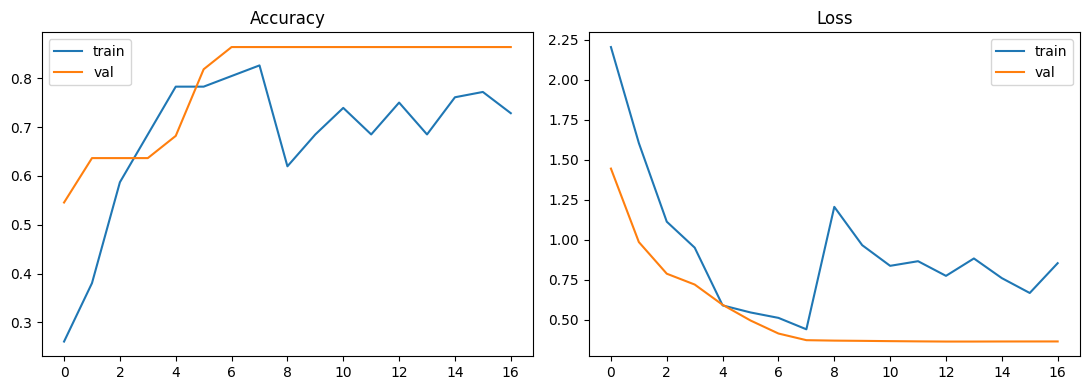

4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 704ms/step - accuracy: 0.9386 - loss: 0.2385
Test accuracy: 0.9386
4/4 ━━━━━━━━━━━━━━━━━━━━ 11s 2s/step
              precision    recall  f1-score   support

   buildings       0.94      0.94      0.94        18
      forest       1.00      1.00      1.00        18
     glacier       0.89      0.94      0.92        18
    mountain       0.88      0.83      0.86        18
         sea       0.96      0.96      0.96        24
      street       0.94      0.94      0.94        18

    accuracy                           0.94       114
   macro avg       0.94      0.94      0.94       114
weighted avg       0.94      0.94      0.94       114



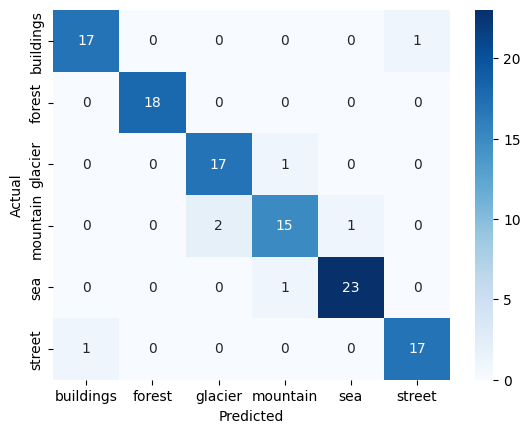

In [7]:
import numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

tf.random.set_seed(42)
IMG_SIZE = (224, 224); BATCH = 32; AUTOTUNE = tf.data.AUTOTUNE
TRAIN_DIR = "C:/Users/LENOVO/Assignments/Linear regression/data/seg_train"
TEST_DIR  = "C:/Users/LENOVO/Assignments/Linear regression/data/seg_train"
CLASSES = ["buildings", "forest", "glacier", "mountain", "sea", "street"]

# 1. Load data (80/20 train/validation split from the training folder)
train_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, class_names=CLASSES, validation_split=0.2, subset="training",
    seed=42, image_size=IMG_SIZE, batch_size=BATCH)
val_ds = keras.utils.image_dataset_from_directory(
    TRAIN_DIR, class_names=CLASSES, validation_split=0.2, subset="validation",
    seed=42, image_size=IMG_SIZE, batch_size=BATCH)
test_ds = keras.utils.image_dataset_from_directory(
    TEST_DIR, class_names=CLASSES, image_size=IMG_SIZE, batch_size=BATCH, shuffle=False)

train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds   = val_ds.cache().prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

# 2. Data augmentation (active only during training)
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomContrast(0.1),



])

# 3. Model: frozen MobileNetV2 base + new classification head
base = MobileNetV2(input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet")
base.trainable = False

inputs = keras.Input(shape=IMG_SIZE + (3,))
x = augment(inputs)
x = preprocess_input(x)                      # scales pixels to [-1, 1]
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(CLASSES), activation="softmax")(x)
model = keras.Model(inputs, outputs)

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2),
    keras.callbacks.ModelCheckpoint("best_scene_model.keras", monitor="val_accuracy", save_best_only=True),
]

# 4a. Stage 1: train only the new head
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h1 = model.fit(train_ds, validation_data=val_ds, epochs=8, callbacks=callbacks)

# 4b. Stage 2: fine-tune the top layers with a low learning rate
base.trainable = True
for layer in base.layers[:-30]:
    layer.trainable = False
model.compile(optimizer=keras.optimizers.Adam(1e-5),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=15, callbacks=callbacks)

# 5. Learning curves
acc  = h1.history["accuracy"] + h2.history["accuracy"]
vacc = h1.history["val_accuracy"] + h2.history["val_accuracy"]
loss = h1.history["loss"] + h2.history["loss"]
vloss= h1.history["val_loss"] + h2.history["val_loss"]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(acc, label="train"); ax[0].plot(vacc, label="val"); ax[0].set_title("Accuracy"); ax[0].legend()
ax[1].plot(loss, label="train"); ax[1].plot(vloss, label="val"); ax[1].set_title("Loss"); ax[1].legend()
plt.tight_layout(); plt.show()

# 6. Evaluate on the held-out test set
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.4f}")

y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_prob = model.predict(test_ds)
y_pred = np.argmax(y_prob, axis=1)
print(classification_report(y_true, y_pred, target_names=CLASSES))
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.show()

# 7. Predict a single new image
def predict_image(path):
    img = keras.utils.load_img(path, target_size=IMG_SIZE)
    arr = np.expand_dims(keras.utils.img_to_array(img), 0)
    p = model.predict(arr)[0]
    print(f"{CLASSES[np.argmax(p)]} ({p.max():.1%})")
# predict_image("sample.jpg")